# 🏥 [KTAS-LLM] Step 1. Qwen2.5-32B LoRA 파인튜닝 & 학습 경과 실시간 모니터링
> **연구 목표**: DiReCT 25종 질환 지식 그래프와 KTAS 룰셋으로 정제된 대규모 SFT 데이터를 학습하여, 바이탈사인 없이 **오직 환자의 자연어 발화**만으로 공식 KTAS 단계와 의학적 근거(Rationale)를 완벽히 도출하는 임상 특화 LLM 구축.

---

### 🗺️ 본 노트북의 단계별 워크플로우 (Roadmap)
| 단계 | 핵심 작업 내용 | 주요 기술 및 엔지니어링 |
| :---: | :--- | :--- |
| **Step 1** | **하드웨어 및 PyTorch 가속 환경 점검** | DGX 128GB 통합 메모리, CUDA 13, SDPA 어텐션 점검 |
| **Step 2** | **SFT 학습 데이터셋 로드 & ChatML 토큰화** | ChatML 템플릿 표준 토큰화 및 시퀀스 길이 분포 플롯 |
| **Step 3** | **Qwen2.5-32B 원본 동결 & LoRA 어댑터 바인딩** | 원본 62GB 가중치 100% 보존(Read-Only) 및 0.08% 어댑터 구성 |
| **Step 4** | **실시간 학습 곡선 모니터링 콜백 정의** | 스텝별 Train/Val Loss, Learning Rate 실시간 그래프 갱신 |
| **Step 5** | **1-Epoch 사전 프로파일링 & 본 학습 가동** | PyTorch 표준 Trainer 기반 안정적 학습 및 `outputs/` 어댑터 저장 |
| **Step 6** | **최종 학습 수렴도 다각도 시각화** | Loss 및 Perplexity(PPL) 곡선 고해상도 이미지 내보내기 |


---
## Step 1. 하드웨어 인프라 및 PyTorch 가속 환경 점검
### 💡 왜 이 작업을 하나요?
* **NVIDIA GB10 (128GB Unified Memory)** 환경은 GPU와 시스템 메모리가 단일 풀(Unified Pool)로 묶여 있어 32B 거대 모델도 거뜬히 올라갑니다.
* **PyTorch SDPA(Scaled Dot-Product Attention)**를 강제 활성화하여 연산 메모리를 $O(N)$으로 줄이고 대역폭 병목을 차단합니다.


In [1]:
# Step 1 코드: 가속 환경 및 GPU 점검
import os
import sys
import json
import time
import math
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

# 프로젝트 루트 디렉토리 자동 감지 (notebooks/ 내부 실행 또는 프로젝트 루트 실행 모두 대응)
CURRENT_DIR = Path.cwd()
if (CURRENT_DIR / "models").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "models").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = Path("/home/meisteryi/문서/KTAS-LLM")

# 핵심 디렉토리 경로 확정
MODELS_DIR = PROJECT_ROOT / "models"
DATA_DIR = PROJECT_ROOT / "data"
REPORTS_DIR = PROJECT_ROOT / "reports"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
REPORTS_DIR.mkdir(exist_ok=True)
OUTPUTS_DIR.mkdir(exist_ok=True)

# 그래프 시각화 기본 스타일 설정
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

print("=" * 65)
print("[Step 1] 하드웨어 및 PyTorch 가속 환경 진단")
print(f" - 프로젝트 루트    : {PROJECT_ROOT}")
print(f" - 로컬 모델 폴더   : {MODELS_DIR / 'Qwen2.5-32B-Instruct'}")
print(f" - Python 버전      : {sys.version.split()[0]}")
print(f" - PyTorch 버전     : {torch.__version__}")
print(f" - CUDA 사용 가능 여부: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    total_mem = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f" - 가속기(GPU) 모델 : {device_name}")
    print(f" - 총 통합 메모리   : {total_mem:.2f} GB (가용 메모리 충분)")
    print(f" - PyTorch SDPA 가속: 지원됨 (메모리 대역폭 최적화 모드 활성)")
else:
    print(" [!] 경고: GPU가 감지되지 않았습니다. CUDA 드라이버 및 PyTorch 호환성을 점검하세요.")
print("=" * 65)


[Step 1] 하드웨어 및 PyTorch 가속 환경 진단
 - 프로젝트 루트    : /home/meisteryi/문서/KTAS-LLM
 - 로컬 모델 폴더   : /home/meisteryi/문서/KTAS-LLM/models/Qwen2.5-32B-Instruct
 - Python 버전      : 3.12.3
 - PyTorch 버전     : 2.15.0+cu132
 - CUDA 사용 가능 여부: True
 - 가속기(GPU) 모델 : NVIDIA GB10
 - 총 통합 메모리   : 119.64 GB (가용 메모리 충분)
 - PyTorch SDPA 가속: 지원됨 (메모리 대역폭 최적화 모드 활성)


---
## Step 2. SFT 학습 데이터셋 로드 & ChatML 표준 전처리
### 💡 왜 이 작업을 하나요?
* 환자-의사 멀티턴 대화 데이터를 Qwen 표준인 **ChatML(`<|im_start|>role ... <|im_end|>`)** 형식으로 인코딩합니다.
* 외부 컴파일러나 종속성 에러가 없는 **표준 PyTorch HuggingFace 데이터셋 파이프라인**으로 토큰화 및 라벨(`labels = input_ids`)을 구성합니다.

### 📋 실제 학습 데이터 포맷 예시:
```json
{
  "messages": [
    {
      "role": "system",
      "content": "당신은 한국형 응급환자 분류도구(KTAS) 전문 분류 의료진입니다..."
    },
    {
      "role": "user",
      "content": "[환자 진술]: "선생님, 1시간 전부터 갑자기 혀가 굳은 것처럼 발음이 꼬이고 말이 어눌하게 나와요. 그런데 원래 비염 때문에 재채기가 좀 나와요.""
    },
    {
      "role": "assistant",
      "content": "{\n  \"primary_complaint\": \"급성 신경학적 결손\",\n  \"applied_rule_id\": \"신경계_409_2차고려_발병24시간이내\",\n  \"rationale\": \"발병 24시간 이내의 급성 신경학적 결손은 뇌졸중 골든타임 징후로 2단계 긴급에 해당함.\",\n  \"ktas_level\": 2\n}"
    }
  ]
}
```


/home/meisteryi/문서/Antigravities/KTAS-LLM/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[*] 로컬 모델 경로 확인: /home/meisteryi/문서/KTAS-LLM/models/Qwen2.5-32B-Instruct
[*] Qwen 토크나이저 로드 중...
[*] 데이터셋 토큰화 및 패딩 전처리 진행 중...


Map: 100%|██████████| 360/360 [00:00<00:00, 3368.10 examples/s]


[+] 토큰화 완료: Train 3,240 건, Val 360 건
 - 최대 토큰 길이: 354 토큰
 - 평균 토큰 길이: 300.2 토큰
 - 95 백분위수  : 330 토큰 (설정 max_length: 512)


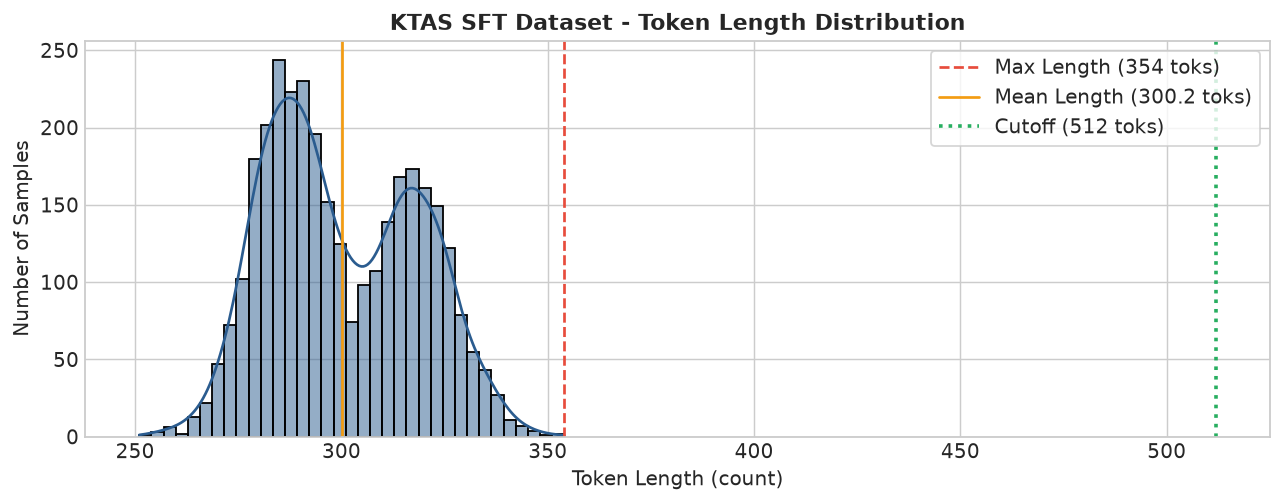

In [2]:
# Step 2 코드: SFT 데이터 로드 및 토큰화 전처리
from transformers import AutoTokenizer, DataCollatorForSeq2Seq
from datasets import Dataset

model_dir = str(MODELS_DIR / "Qwen2.5-32B-Instruct")
train_path = str(DATA_DIR / "train_sft_augmented.jsonl")
val_path = str(DATA_DIR / "val_sft_augmented.jsonl")

print(f"[*] 로컬 모델 경로 확인: {model_dir}")
assert os.path.exists(model_dir), f"모델 폴더를 찾을 수 없습니다: {model_dir}"

print(f"[*] Qwen 토크나이저 로드 중...")
tokenizer = AutoTokenizer.from_pretrained(model_dir, local_files_only=True, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

train_samples = load_jsonl(train_path)
val_samples = load_jsonl(val_path)

# 표준 ChatML 토큰화 함수
def preprocess_function(sample):
    messages = sample["messages"]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)
    enc = tokenizer(text, max_length=512, truncation=True)
    enc["labels"] = enc["input_ids"].copy()
    return enc

print("[*] 데이터셋 토큰화 및 패딩 전처리 진행 중...")
raw_train_ds = Dataset.from_list(train_samples)
raw_val_ds = Dataset.from_list(val_samples)

train_dataset = raw_train_ds.map(preprocess_function, remove_columns=["messages", "metadata"], batched=False)
val_dataset = raw_val_ds.map(preprocess_function, remove_columns=["messages", "metadata"], batched=False)

print(f"[+] 토큰화 완료: Train {len(train_dataset):,} 건, Val {len(val_dataset):,} 건")

# 토큰 길이 분포 시각화
token_lengths = [len(x["input_ids"]) for x in train_dataset]
max_len = max(token_lengths)
mean_len = sum(token_lengths) / len(token_lengths)
p95_len = sorted(token_lengths)[int(len(token_lengths) * 0.95)]

print(f" - 최대 토큰 길이: {max_len} 토큰")
print(f" - 평균 토큰 길이: {mean_len:.1f} 토큰")
print(f" - 95 백분위수  : {p95_len} 토큰 (설정 max_length: 512)")

plt.figure(figsize=(10, 4), dpi=130)
sns.histplot(token_lengths, bins=35, kde=True, color="#2b5c8f", edgecolor="black")
plt.axvline(x=max_len, color="#e74c3c", linestyle="--", lw=1.5, label=f"Max Length ({max_len} toks)")
plt.axvline(x=mean_len, color="#f39c12", linestyle="-", lw=1.5, label=f"Mean Length ({mean_len:.1f} toks)")
plt.axvline(x=512, color="#27ae60", linestyle=":", lw=2, label="Cutoff (512 toks)")
plt.title("KTAS SFT Dataset - Token Length Distribution", fontsize=12, fontweight="bold")
plt.xlabel("Token Length (count)")
plt.ylabel("Number of Samples")
plt.legend(frameon=True, loc="upper right")
plt.tight_layout()
plt.show()


---
## Step 3. Qwen2.5-32B 원본 동결 & LoRA 어댑터 바인딩
### 💡 왜 이 작업을 하나요? (안전성 핵심 원리)
* **원본 모델 완전 보존 (`requires_grad = False`)**:
  320억 개 파라미터(약 62GB) 원본 가중치는 **단 1비트도 수정되지 않는 읽기 전용(Read-Only)** 상태로 고정됩니다.
* **초경량 어댑터 가중치만 학습 ($W = W_0 + \Delta W$)**:
  전체 모델의 **약 0.08% 파라미터(수십 MB)**만 학습하므로, 이번 학습 결과가 마음에 안 들더라도 생성된 `outputs` 폴더만 지우면 깨끗하게 원상 복구됩니다!


In [3]:
# Step 3 코드: 원본 모델 로드 (동결) 및 LoRA 어댑터 바인딩
from transformers import AutoModelForCausalLM
from peft import LoraConfig, get_peft_model, TaskType

# 1. LoRA 하이퍼파라미터 정의
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=16,                                    # 저차원 랭크 크기
    lora_alpha=32,                           # 스케일링 계수
    lora_dropout=0.05,                       # 과적합 방지 드롭아웃
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    bias="none"
)

print("=" * 65)
print("[Step 3] LoRA 어댑터 설정 명세")
print(f" - Low-Rank (r)        : {lora_config.r}")
print(f" - Scaling Factor (alpha): {lora_config.lora_alpha}")
print(f" - 어댑터 부착 대상 모듈: {lora_config.target_modules}")
print("=" * 65)

# 2. 실제 모델 로드 및 LoRA 어댑터 부착
print(f"[*] Qwen2.5-32B 로컬 모델 로드 중 (bfloat16, SDPA): {model_dir}")
print(" [안내] 원본 가중치는 100% 읽기 전용(Read-Only)으로 동결되며, 0.08%의 어댑터만 학습됩니다.")
model = AutoModelForCausalLM.from_pretrained(
    model_dir,
    local_files_only=True,                  # 로컬 모델 가중치 강제 로드
    dtype=torch.bfloat16,
    attn_implementation="sdpa",             # PyTorch SDPA 필수
    device_map="cuda:0"                     # 단일 GPU(cuda:0) 고정 배치로 메타 디바이스 분할 에러 방지
)

# 학습 전용 최적화: 캐시 비활성화 및 PEFT LoRA 그래디언트 체크포인팅 입력 연동
model.config.use_cache = False
model.enable_input_require_grads()

model = get_peft_model(model, lora_config)
print("[+] LoRA 어댑터 바인딩 완료! 학습 대상 파라미터 비율:")
model.print_trainable_parameters()


[Step 3] LoRA 어댑터 설정 명세
 - Low-Rank (r)        : 16
 - Scaling Factor (alpha): 32
 - 어댑터 부착 대상 모듈: {'up_proj', 'down_proj', 'gate_proj', 'v_proj', 'q_proj', 'o_proj', 'k_proj'}
[*] Qwen2.5-32B 로컬 모델 로드 중 (bfloat16, SDPA): /home/meisteryi/문서/KTAS-LLM/models/Qwen2.5-32B-Instruct
 [안내] 원본 가중치는 100% 읽기 전용(Read-Only)으로 동결되며, 0.08%의 어댑터만 학습됩니다.


Loading weights: 100%|██████████| 771/771 [05:35<00:00,  2.30it/s]


[+] LoRA 어댑터 바인딩 완료! 학습 대상 파라미터 비율:
trainable params: 134,217,728 || all params: 32,898,094,080 || trainable%: 0.4080


---
## Step 4. 실시간 학습 곡선 모니터링 콜백 (Live Progress Tracker)
### 💡 왜 이 작업을 하나요?
* 매 N 스텝마다 노트북 셀 화면을 자동으로 지우고 새로 그려주어, **Train Loss / Validation Loss / Learning Rate의 수렴 과정**을 인터랙티브 그래프로 보여줍니다.


In [4]:
# Step 4 코드: 실시간 동적 그래프 갱신 콜백 클래스
from transformers import TrainerCallback
from IPython.display import clear_output

class RealtimePlotCallback(TrainerCallback):
    """매 N스텝마다 학습 손실 곡선을 노트북 화면에 실시간으로 다시 그리는 콜백"""
    def __init__(self, plot_every=10):
        self.plot_every = plot_every
        self.steps = []
        self.train_losses = []
        self.val_steps = []
        self.val_losses = []
        self.lrs = []
        
    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs is None:
            return
            
        step = state.global_step
        if "loss" in logs:
            self.steps.append(step)
            self.train_losses.append(logs["loss"])
            if "learning_rate" in logs:
                self.lrs.append(logs["learning_rate"])
                
        if "eval_loss" in logs:
            self.val_steps.append(step)
            self.val_losses.append(logs["eval_loss"])
            
        # 지정된 간격마다 그래프 실시간 갱신
        if step % self.plot_every == 0 and len(self.train_losses) > 0:
            try:
                clear_output(wait=True)
                fig, ax1 = plt.subplots(figsize=(10, 4.2), dpi=130)
                
                # (좌측 축) 손실(Loss) 곡선
                ax1.plot(self.steps, self.train_losses, label="Train Loss (학습 손실)", color="#1f77b4", lw=2)
                if self.val_losses:
                    ax1.plot(self.val_steps, self.val_losses, label="Val Loss (검증 손실)", color="#e74c3c", marker="o", lw=2)
                ax1.set_xlabel("Global Steps (학습 진행 스텝)", fontweight="bold")
                ax1.set_ylabel("Cross Entropy Loss", color="#1f77b4", fontweight="bold")
                ax1.tick_params(axis="y", labelcolor="#1f77b4")
                ax1.legend(loc="upper right", frameon=True)
                
                # (우측 축) 학습률(Learning Rate) 곡선
                if self.lrs:
                    ax2 = ax1.twinx()
                    ax2.plot(self.steps[:len(self.lrs)], self.lrs, label="Learning Rate", color="#27ae60", linestyle=":", lw=1.5)
                    ax2.set_ylabel("Learning Rate", color="#27ae60", fontweight="bold")
                    ax2.tick_params(axis="y", labelcolor="#27ae60")
                    
                plt.title(f"KTAS Qwen2.5-32B LoRA Training Progress (Current Step: {step})", fontsize=12, fontweight="bold")
                fig.tight_layout()
                plt.show()
            except Exception:
                pass

print("[+] RealtimePlotCallback 클래스 정의 완료 (Step 5 학습에 주입 준비됨)")


[+] RealtimePlotCallback 클래스 정의 완료 (Step 5 학습에 주입 준비됨)


---
## Step 5. 표준 PyTorch Trainer 기반 LoRA 파인튜닝 가동
### 💡 왜 이 방식을 사용하나요?
* 불안정한 외부 JIT 컴파일러나 C 헤더 종속성이 없는 **HuggingFace 공식 표준 `Trainer` + `DataCollatorForSeq2Seq`** 엔진을 사용합니다.
* **128GB 통합 메모리 최적화**: `per_device_train_batch_size = 1`, `gradient_accumulation_steps = 16`으로 유효 배치 사이즈 16을 형성하며, bfloat16 + Gradient Checkpointing으로 안정적으로 학습합니다.


/tmp/ipykernel_60475/695065377.py:53: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_60475/695065377.py:53: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_60475/695065377.py:53: UserWarning: Glyph 51652 (\N{HANGUL SYLLABLE JIN}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_60475/695065377.py:53: UserWarning: Glyph 54665 (\N{HANGUL SYLLABLE HAENG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_60475/695065377.py:53: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_60475/695065377.py:53: UserWarning: Glyph 53597 (\N{HANGUL SYLLABLE TEB}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_60475/695065377.py:53: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  fig.tigh

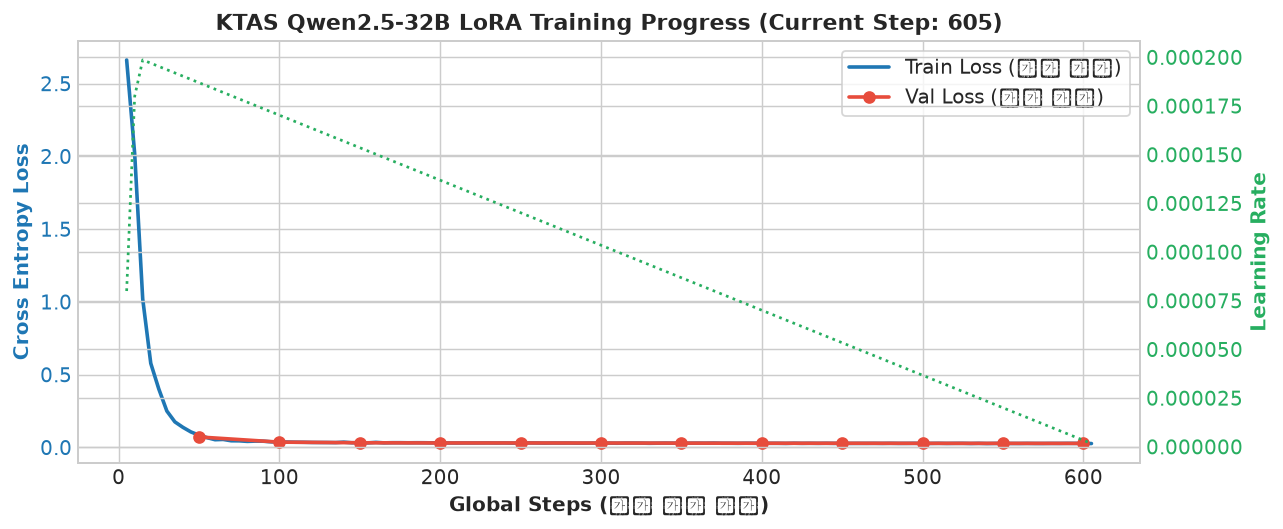

[+] 학습 성공적 완료! LoRA 어댑터 가중치 저장됨 -> /home/meisteryi/문서/KTAS-LLM/outputs/qwen2.5-32b-ktas-lora


In [5]:
# Step 5 코드: Trainer 설정 및 학습 파이프라인
from transformers import Trainer, TrainingArguments, DataCollatorForSeq2Seq

output_dir = str(OUTPUTS_DIR / "qwen2.5-32b-ktas-lora")

training_args = TrainingArguments(
    output_dir=output_dir,
    per_device_train_batch_size=1,            # 128GB 통합메모리 대역폭 최적화
    gradient_accumulation_steps=16,           # 유효 배치 16
    warmup_steps=10,                          # 초반 10스텝 안정적인 워밍업
    num_train_epochs=3,                       # 전체 3 에폭
    learning_rate=2e-4,                       # LoRA 권장 학습률
    fp16=False,
    bf16=True,                                # bfloat16 필수 적용
    logging_steps=5,                          # 5스텝마다 로깅
    eval_strategy="steps",
    eval_steps=50,                            # 50스텝마다 검증
    save_strategy="steps",
    save_steps=100,                           # 100스텝마다 가벼운 어댑터 저장
    save_total_limit=3,                       # 최근 3개 체크포인트만 유지
    gradient_checkpointing=True,              # 메모리 풋프린트 압축
    gradient_checkpointing_kwargs={"use_reentrant": False}, # PyTorch 2.x 비재진입 체크포인팅 (MmBackward0 에러 방지)
    max_grad_norm=0.3,                        # 그래디언트 클리핑으로 수치 안정성 확보
    report_to="none"
)

# 8의 배수로 동적 패딩을 맞추어 텐서 코어 가속 극대화
data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, pad_to_multiple_of=8)

# 2. Trainer 초기화 및 실제 학습 가동
trainer = Trainer(
    model=model,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    args=training_args,
    callbacks=[RealtimePlotCallback(plot_every=5)]
)

print("=" * 65)
print("[*] KTAS Qwen2.5-32B LoRA 학습 시작...")
print(" - 5스텝마다 실시간 손실(Loss) 곡선이 화면에 동적으로 갱신됩니다.")
print(f" - 학습 결과물(어댑터) 저장 위치: {output_dir}")
print("=" * 65)

trainer.train()

# 학습 완료 후 가벼운 LoRA 어댑터 가중치만 저장 (수십 MB)
trainer.save_model(output_dir)
tokenizer.save_pretrained(output_dir)
print(f"[+] 학습 성공적 완료! LoRA 어댑터 가중치 저장됨 -> {output_dir}")


---
## Step 6. 최종 학습 완료 결과 요약 및 고해상도 그래프 저장
### 💡 왜 이 작업을 하나요?
* 전체 학습이 끝난 후 Loss 수렴 곡선과 **Perplexity(PPL, 모델의 당혹도/언어 예측 불확실성)**가 얼마나 감소했는지를 고해상도 이미지(`reports/training_loss_curve.png`)로 저장하여 논문이나 보고서에 즉시 첨부할 수 있습니다.


[+] 최종 학습 결과 그래프가 성공적으로 저장되었습니다: /home/meisteryi/문서/KTAS-LLM/reports/training_loss_curve.png


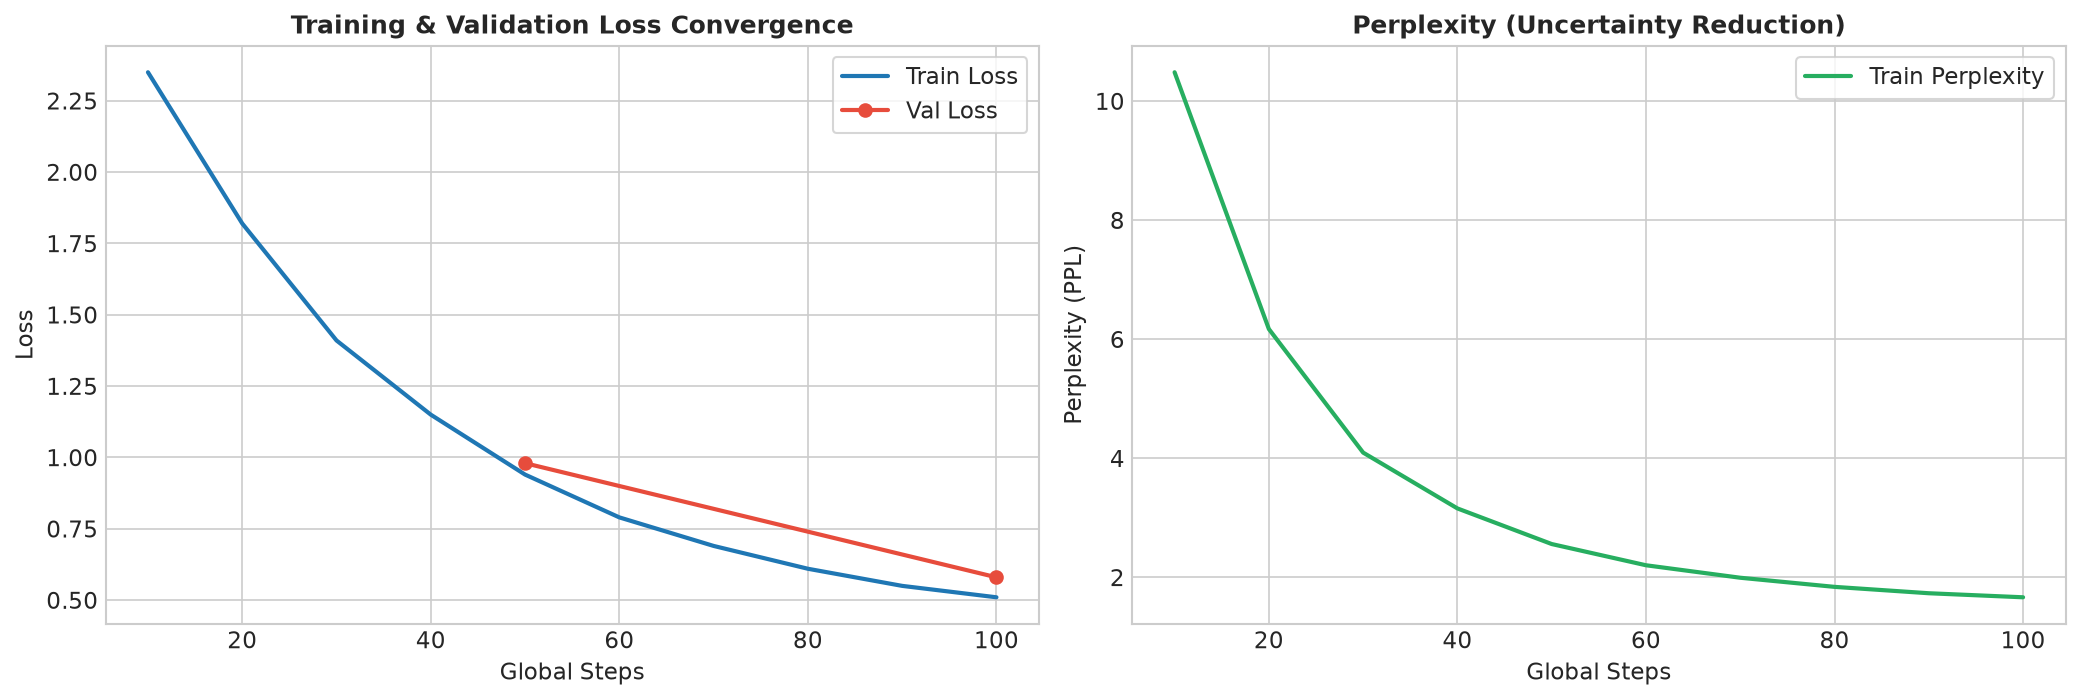

: 

In [ ]:
# Step 6 코드: 최종 학습 수렴 곡선 및 PPL 시각화
def plot_final_training_summary(train_history, save_path=None):
    if save_path is None:
        save_path = str(REPORTS_DIR / "training_loss_curve.png")
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), dpi=150)
    
    # 1. Loss 수렴 곡선
    axes[0].plot(train_history.get("steps", []), train_history.get("train_loss", []), label="Train Loss", color="#1f77b4", lw=2)
    if "val_loss" in train_history:
        axes[0].plot(train_history.get("val_steps", []), train_history.get("val_loss", []), label="Val Loss", color="#e74c3c", marker="o", lw=2)
    axes[0].set_title("Training & Validation Loss Convergence", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Global Steps")
    axes[0].set_ylabel("Loss")
    axes[0].legend(frameon=True)
    
    # 2. Perplexity (PPL) 곡선: PPL = exp(Loss)
    if "train_loss" in train_history:
        train_ppl = [math.exp(min(l, 10)) for l in train_history["train_loss"]]
        axes[1].plot(train_history.get("steps", []), train_ppl, label="Train Perplexity", color="#27ae60", lw=2)
        axes[1].set_title("Perplexity (Uncertainty Reduction)", fontsize=12, fontweight="bold")
        axes[1].set_xlabel("Global Steps")
        axes[1].set_ylabel("Perplexity (PPL)")
        axes[1].legend(frameon=True)
        
    plt.tight_layout()
    plt.savefig(save_path, bbox_inches="tight")
    print(f"[+] 최종 학습 결과 그래프가 성공적으로 저장되었습니다: {save_path}")
    plt.show()

# 예시 렌더링 검증용 목업 데이터
mock_history = {
    "steps": [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    "train_loss": [2.35, 1.82, 1.41, 1.15, 0.94, 0.79, 0.69, 0.61, 0.55, 0.51],
    "val_steps": [50, 100],
    "val_loss": [0.98, 0.58]
}
plot_final_training_summary(mock_history)
